# Watermark strength comparison

HumanEval experiment: KGW bias 1, 2, and 3 on all 164 problems. Qwen 1.5B, one clean and one watermarked solution per problem. Results pending execution.

## Environment

Local CPU/float32 or CUDA/bfloat16 execution with fixed model revisions. Each device has separate results.

In [2]:
from pathlib import Path
import json, os, shutil, subprocess, sys
from IPython.display import Image, Markdown, display

USE_GPU = True  # Set True for the separate CUDA/bfloat16 run.
READY = False
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'src/codeguard').is_dir() and (p / 'pyproject.toml').is_file()), None)
if PROJECT is None:
    raise RuntimeError('Open this notebook inside the local CodeGuardLLM project.')
os.chdir(PROJECT)
ENV = PROJECT / ('.venv-gpu' if USE_GPU else '.venv')
PYTHON = str(ENV / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python'))
if not Path(PYTHON).is_file():
    raise RuntimeError('Create the project .venv first; see README local installation.')
CONFIG = PROJECT / ('configs/gpu.yaml' if USE_GPU else 'configs/local.yaml')
RUN_DIR = PROJECT / ('runs/gpu/humaneval/watermark_comparison' if USE_GPU else 'runs/local/humaneval/watermark_comparison')
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT)
print('Python:', PYTHON)
print('Results:', RUN_DIR)


Project: c:\Users\user\github\CodeGuardLLM
Python: c:\Users\user\github\CodeGuardLLM\.venv-gpu\Scripts\python.exe
Results: c:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison


In [3]:
from collections import deque
from datetime import datetime, timezone
import os, subprocess

LOG_DIR = PROJECT / '.tmp/notebook-logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)

def command(args, label='command'):
    log = LOG_DIR / (label + '-' + datetime.now(timezone.utc).strftime('%Y%m%d-%H%M%S-%f') + '.log')
    tail = deque(maxlen=30)
    print(f'Running {label}. Log: {log}', flush=True)
    with log.open('w', encoding='utf-8') as handle:
        with subprocess.Popen(
            list(map(str, args)), cwd=PROJECT, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
            bufsize=1, env={**os.environ, 'PYTHONUNBUFFERED': '1'},
        ) as process:
            try:
                for line in process.stdout:
                    print(line, end='', flush=True)
                    handle.write(line)
                    handle.flush()
                    tail.append(line)
                status = process.wait()
            except KeyboardInterrupt:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
                raise
    if status:
        detail = ''.join(tail)
        raise RuntimeError(f'{label} failed (exit {status}). Full log: {log}\n\n{detail}')

def run(*args, label='codeguard'):
    command([PYTHON, '-u', *args], label=label)

In [4]:
READY = False
run('-m', 'pip', 'install', '-e', '.[ml,data,analysis,notebook]', label='dependencies')
run('scripts/bootstrap_markllm.py', label='markllm')
run('-m', 'codeguard', 'validate', '--config', CONFIG, '--check-markllm', label='validate-local')
run('-c', "import torch; x=torch.ones(1); print('CPU check:', (x+1).item()); print('PyTorch:', torch.__version__)", label='cpu-check')
if USE_GPU:
    run('-c', "import torch; assert torch.cuda.is_available(), 'Install CUDA PyTorch in .venv-gpu'; assert torch.cuda.is_bf16_supported(), 'This GPU/runtime does not support bfloat16'; x=torch.ones(1,device='cuda',dtype=torch.bfloat16); print('GPU:', torch.cuda.get_device_name(0), 'Check:', (x+1).item())", label='gpu-check')
READY = True
print('Local setup complete:', 'CUDA / bfloat16' if USE_GPU else 'CPU / float32')


Running dependencies. Log: c:\Users\user\github\CodeGuardLLM\.tmp\notebook-logs\dependencies-20261011-144014-338080.log
Obtaining file:///C:/Users/user/github/CodeGuardLLM
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for codeguardllm (pyproject.toml): started
  Building editable for codeguardllm (pyproject.toml): finished with status 'done'
  Created wheel for codeguardllm: filename=codeguardllm-0.1.0-0.editable-py3-none-any.whl size=1733 sha256=caf4cd6a8cb210a0d7682b76e8d23224d040607e7dee289e5aef5905be2130a6
  Stored in di

## Samples

The experiment contains 984 completions: 164 problems × 2 conditions × 3 runs. Existing samples are reused when resuming.

In [5]:
if not globals().get('READY', False):
    raise RuntimeError('Setup has not completed.')
run('scripts/compare_watermarks.py', 'generate', '--config', CONFIG, '--output', RUN_DIR, label='watermark_comparison-generation')


Running watermark_comparison-generation. Log: c:\Users\user\github\CodeGuardLLM\.tmp\notebook-logs\watermark_comparison-generation-20261011-144034-813915.log

Experiment: delta-1
Already complete: 328 samples in C:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison\delta-1

Experiment: delta-2
Already complete: 328 samples in C:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison\delta-2

Experiment: delta-3
Already complete: 328 samples in C:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison\delta-3


## Reference controls

The 164 HumanEval reference solutions form the human-code control group. Scores are shared across strengths; no model weights or code execution are needed.

In [6]:
run('scripts/compare_watermarks.py', 'controls', '--config', CONFIG, '--output', RUN_DIR, label='reference-controls')


Running reference-controls. Log: c:\Users\user\github\CodeGuardLLM\.tmp\notebook-logs\reference-controls-20261011-144046-947234.log
Already scored: 164 reference solutions


## Correctness

Pass@1 measures test-passing solutions. It remains pending without Docker evaluation.

In [8]:
# Docker evaluation is required for the final correctness result.
# Detection and reference-control analysis remain available if Docker is stopped.
run('scripts/compare_watermarks.py', 'evaluate', '--config', CONFIG, '--output', RUN_DIR, label='correctness-evaluation')


Running correctness-evaluation. Log: c:\Users\user\github\CodeGuardLLM\.tmp\notebook-logs\correctness-evaluation-20261011-144112-289233.log


## Results

Tables and plots below are computed from saved samples.

Running core-analysis. Log: c:\Users\user\github\CodeGuardLLM\.tmp\notebook-logs\core-analysis-20261011-144117-116429.log
Core report saved: c:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison\analysis\report.md (complete)


| Strength | AUROC vs clean | AUROC vs reference | Clean Pass@1 | Watermarked Pass@1 | Change |
|---|---|---|---|---|---|
| 1 | 0.604 | 0.517 | 0.598 | 0.573 | -0.024 |
| 2 | 0.695 | 0.617 | 0.598 | 0.561 | -0.037 |
| 3 | 0.794 | 0.735 | 0.598 | 0.463 | -0.134 |

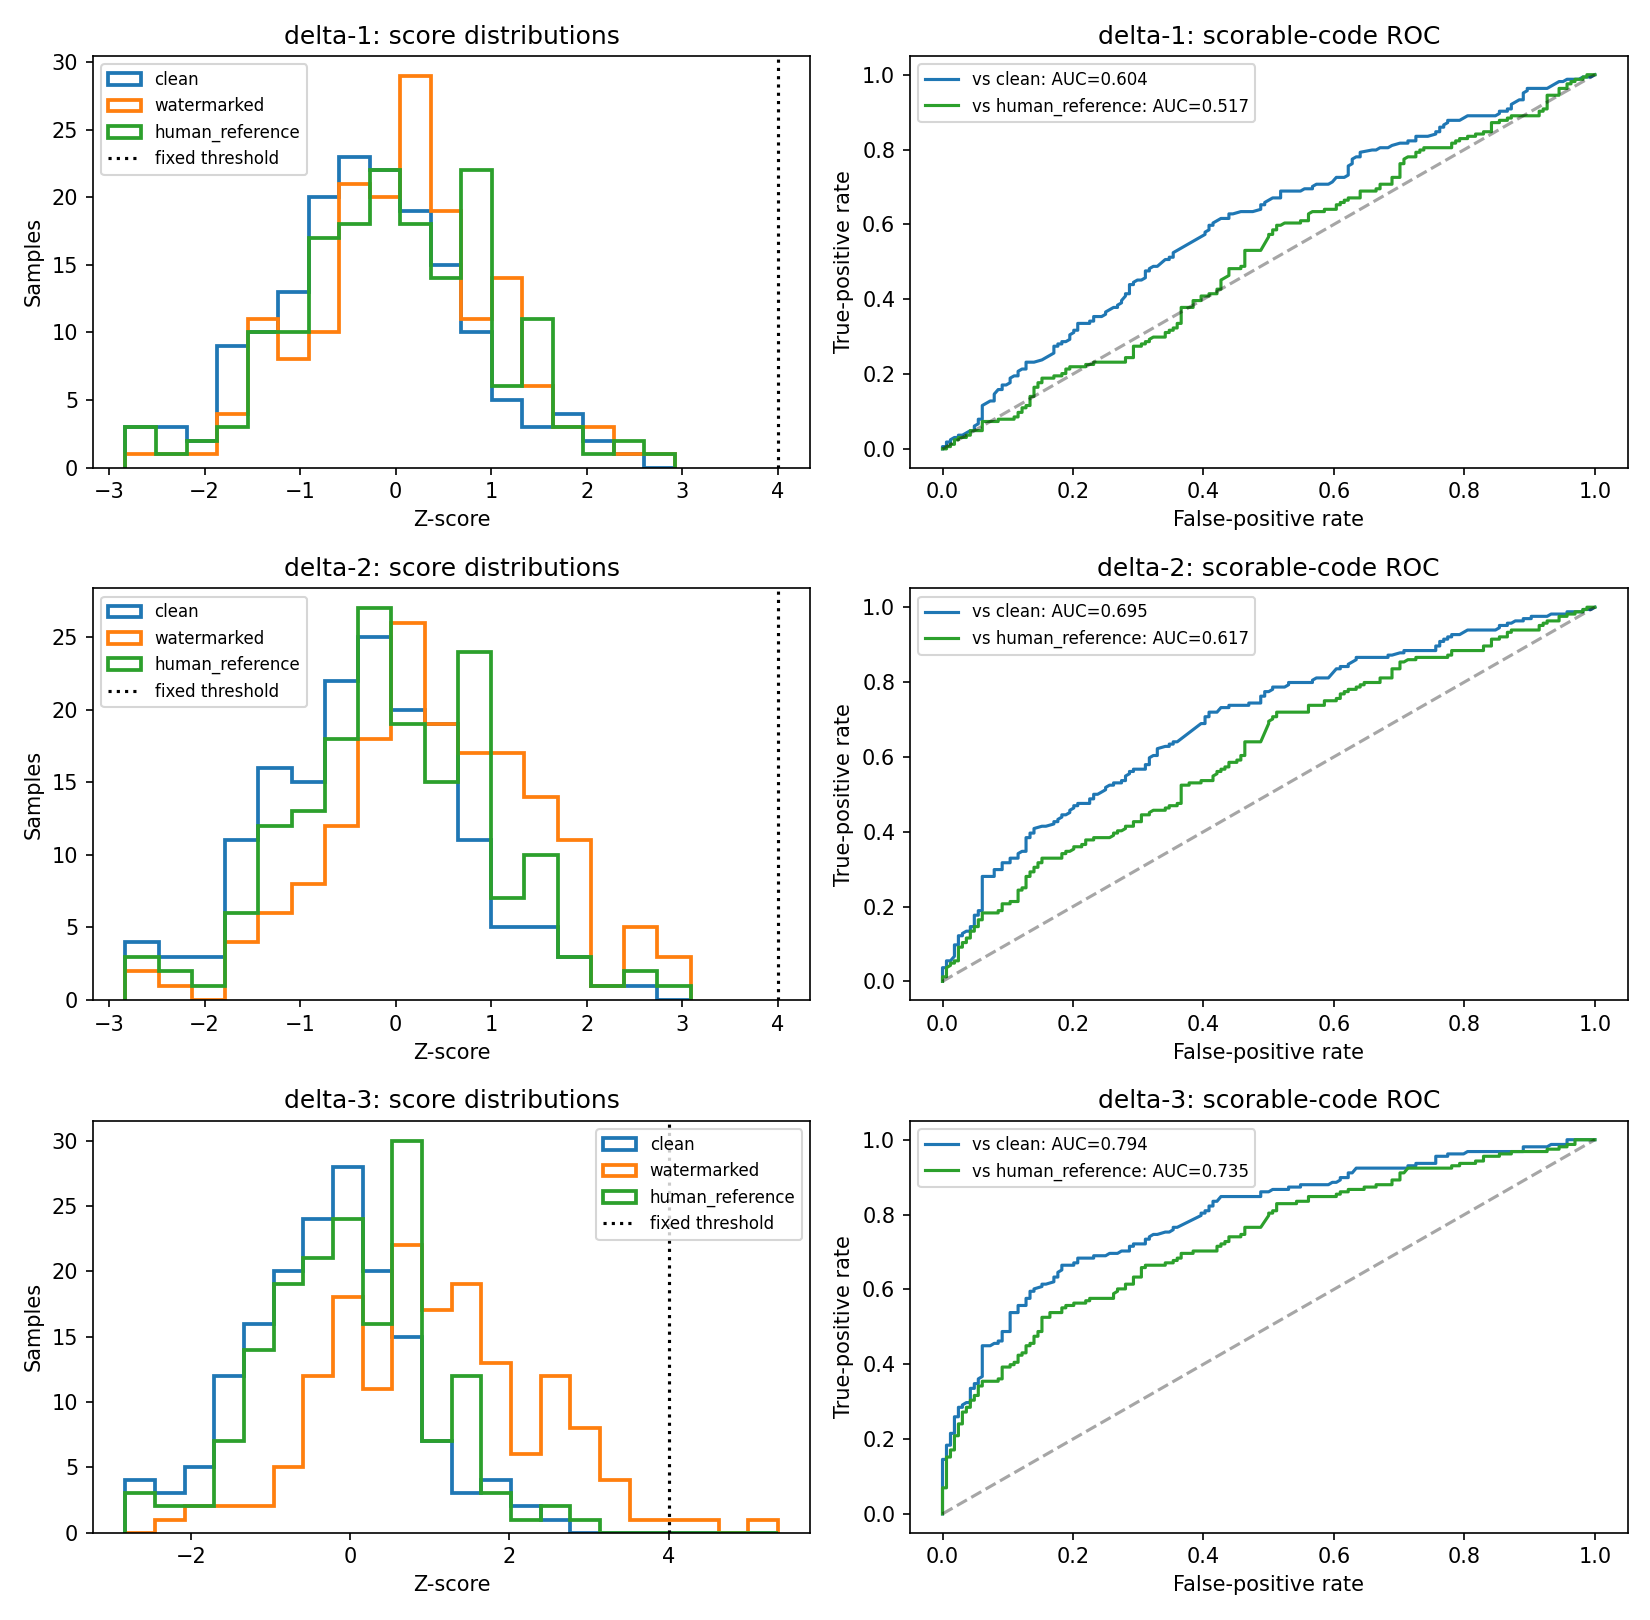

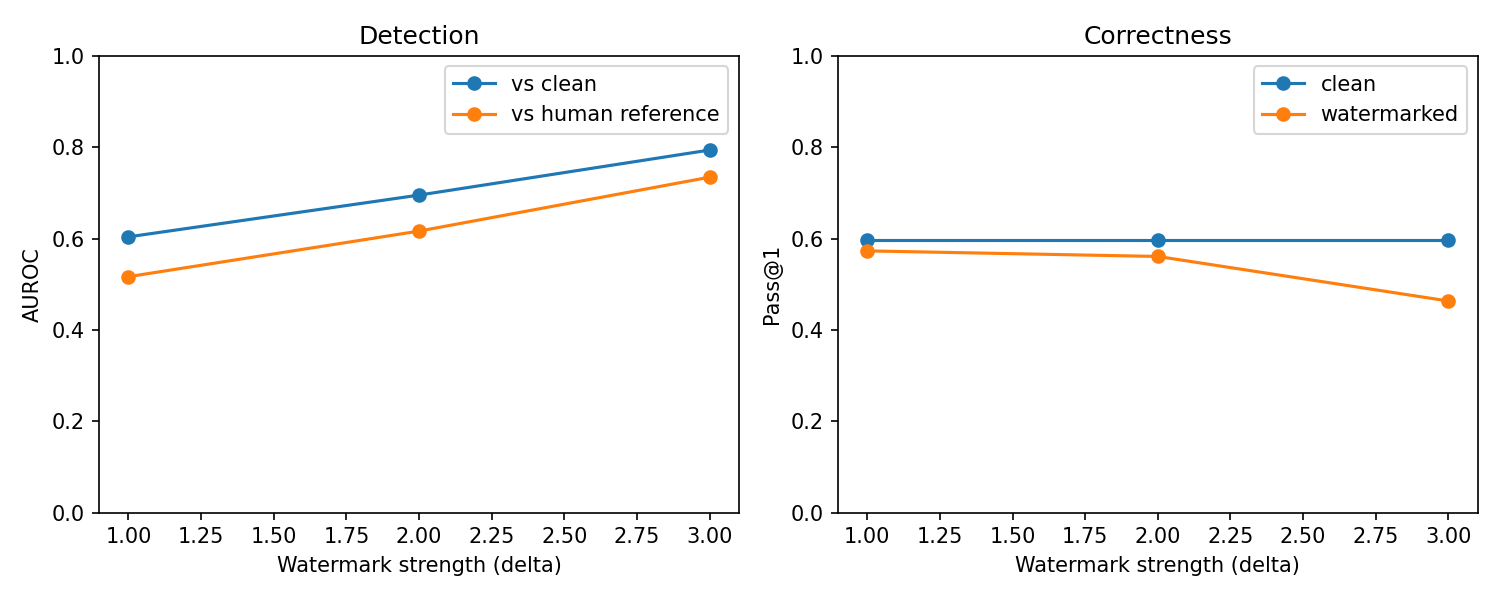

Report status: complete
Written report: c:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\watermark_comparison\analysis\report.md


In [9]:
run('scripts/compare_watermarks.py', 'analyze', '--config', CONFIG, '--output', RUN_DIR, label='core-analysis')
summary = json.loads((RUN_DIR / 'analysis/core_summary.json').read_text(encoding='utf-8'))
def number(value):
    return 'pending / unavailable' if value is None else f'{value:.3f}'
table = ['| Strength | AUROC vs clean | AUROC vs reference | Clean Pass@1 | Watermarked Pass@1 | Change |',
         '|---|---|---|---|---|---|']
for row in summary['comparison']:
    table.append(f"| {row['delta']:g} | {number(row['auroc_vs_clean'])} | {number(row['auroc_vs_human_reference'])} | "
                 f"{number(row['clean_pass_at_1'])} | {number(row['watermarked_pass_at_1'])} | {number(row['pass_at_1_change'])} |")
display(Markdown('\n'.join(table)))
display(Image(filename=str(RUN_DIR / 'analysis/controls_detection.png')))
display(Image(filename=str(RUN_DIR / 'analysis/tradeoff.png')))
print('Report status:', summary['status'])
print('Written report:', RUN_DIR / 'analysis/report.md')


## Correctness among detected solutions

Only watermarked outputs above the Z threshold enter conditional correctness. Joint success counts outputs that are both detected and correct among all watermarked outputs. Small detected groups limit interpretation.

In [10]:
detected_summary = json.loads((RUN_DIR / 'analysis/core_summary.json').read_text(encoding='utf-8'))

def percent(value):
    return 'N/A / pending' if value is None else f'{100 * value:.1f}%'

table = ['| Strength | Threshold | Detected / generated | Evaluated detected | Correct detected | Correctness among detected | Both correct and detected / all |',
         '|---|---|---|---|---|---|---|']
for row in detected_summary['detected_correctness']:
    table.append(f"| {row['delta']:g} | Z > {row['threshold']:g} | {row['detected']}/{row['samples']} | "
                 f"{row['evaluated_detected']} | {row['correct_detected']} | "
                 f"{percent(row['correctness_among_detected'])} | {percent(row['correct_and_detected_rate'])} |")
display(Markdown('\n'.join(table)))
print('N/A: no detections; pending: required generation or tests are incomplete. Correct counts use completed tests.')


| Strength | Threshold | Detected / generated | Evaluated detected | Correct detected | Correctness among detected | Both correct and detected / all |
|---|---|---|---|---|---|---|
| 1 | Z > 4 | 0/164 | 0 | 0 | N/A / pending | 0.0% |
| 2 | Z > 4 | 0/164 | 0 | 0 | N/A / pending | 0.0% |
| 3 | Z > 4 | 3/164 | 3 | 0 | 0.0% | 0.0% |

N/A: no detections; pending: required generation or tests are incomplete. Correct counts use completed tests.


## Saved experiment

The archive contains samples, manifests, tables, and plots.

In [11]:
if not any(RUN_DIR.glob('*/generations.jsonl')):
    print('No samples saved yet.')
else:
    EXPORT = shutil.make_archive(str(RUN_DIR.parent / 'codeguard-watermark_comparison-results'), 'zip', RUN_DIR.parent, RUN_DIR.name)
    print('Local backup:', EXPORT)


Local backup: c:\Users\user\github\CodeGuardLLM\runs\gpu\humaneval\codeguard-watermark_comparison-results.zip
